### 实验4 基于小数据集的CNN应用(2 爬取图像数据集并建模)

奶龙、奶蛙、水豚噜噜、Loopy，每类250张。统一划分训练／验证／测试集，比较CNN、数据增强、VGG16与InceptionV3。

#### 一、图片爬取与数据划分
##### 1.1 爬取与核查

（1）Bing图片检索下载原图；原图不可用时尝试检索缩略图。保留可解码、短边≥96像素、长宽比≤2.6的图片；透明背景合成白色，动图保留第一帧。

（2）记录关键词、原图地址和来源页；用像素摘要与感知哈希去重。按角色外形核查保留图，剔除搜索串类、真实动物、其他卡通、广告页面和多角色合集。

（3）本次已完成下载与核查，默认复用本地数据；需要重新检索时才开启`RECRAWL`。重新爬取后应重新核查白名单。

In [1]:
"""Bing 图片检索；下载、校验与去重，来源记录单独保存。"""
import concurrent.futures as cf
import hashlib, html, json, re, time, threading
from io import BytesIO
from pathlib import Path
import requests
import numpy as np
from PIL import Image, ImageOps
from bs4 import BeautifulSoup
from scipy.fft import dctn

# 爬取缓存与最终data目录分开保存，候选图不直接进入训练集。
ROOT = Path.cwd()
# 将缓存、日志、训练历史和导出模型统一写入辅助文件夹。
AUX = ROOT / '辅助文件'
CACHE = AUX / '.cache/crawl'
AUX = ROOT / '辅助文件'
OUT = AUX / 'outputs'
OUT.mkdir(exist_ok=True)
# 使用服务器现有HTTP代理；重新爬取时需保证该代理可连接。
PROXY = 'http://127.0.0.1:17899'
# 多组关键词扩展同一角色的表情与姿态，检索类别仍需逐张核查。
QUERIES = {
 'loopy': ['loopy表情包', 'loopy露比 表情包', 'loopy 可爱', 'loopy 头像', 'loopy 搞笑', 'loopy 微信表情', 'loopy 露比 动图', 'loopy 表情包 单张'],
 'lulu': ['水豚噜噜表情包', '水豚噜噜 可爱', '水豚噜噜 头像', '水豚噜噜 搞笑', '水豚噜噜 动图', '水豚噜噜 微信表情', '噜噜 水豚 表情包', '水豚噜噜 表情包 单张'],
 'nailong': ['奶龙表情包', '奶龙 可爱 表情', '奶龙 头像', '奶龙 搞笑 表情包', '奶龙 动图', '奶龙 微信表情', '奶龙 表情包 单张', '奶龙 生气 开心'],
 'naiwa': ['奶蛙表情包', '奶蛙 可爱', '奶蛙 头像', '奶蛙 搞笑', '奶蛙 动图', '奶蛙 微信表情', '奶蛙 表情包 单张', '奶蛙 生气 开心'],
}
HEADERS = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 Chrome/131.0 Safari/537.36'}
local = threading.local()
# 各下载线程独立复用连接，避免多个线程共享可变会话。
def session():
 if not hasattr(local, 's'):
  local.s=requests.Session(); local.s.proxies.update({'http':PROXY,'https':PROXY}); local.s.headers.update(HEADERS)
 return local.s

# 按关键词和页码检索，保存原图、缩略图、来源页及标题。
def search(job):
 category,query,first=job
 try:
  r=session().get('https://www.bing.com/images/search',params={'q':query,'first':first,'count':35,'form':'HDRSC3'},timeout=20)
  r.raise_for_status()
  result=[]
  for a in BeautifulSoup(r.text,'html.parser').select('a.iusc'):
   m=json.loads(a['m']); result.append({'category':category,'query':query,'image_url':m.get('murl'), 'thumbnail_url':m.get('turl'),'page_url':m.get('purl'),'title':m.get('t','')})
  return result
 except Exception as e:
  print('search failed',category,query,first,type(e).__name__,flush=True); return []

# 用缩放后的像素摘要识别重复内容，用DCT低频感知哈希识别相近图片。
def fingerprints(im):
 a=np.asarray(ImageOps.grayscale(im).resize((32,32),Image.Resampling.LANCZOS),dtype=float)
 # 去掉反映整体亮度的直流分量，再按低频系数中位数二值化。
 low=dctn(a,type=2,norm='ortho')[:8,:8].flatten()[1:]
 ph=sum(int(v>np.median(low))<<i for i,v in enumerate(low))
 sha=hashlib.sha256(np.asarray(im.resize((128,128))).tobytes()).hexdigest()
 return sha,ph

# 原图失败时尝试缩略图；下载后先校验尺寸与解码结果，再保存。
def download(m):
 for kind in ['image_url','thumbnail_url']:
  url=m.get(kind)
  if not url or not url.startswith('http'): continue
  try:
   r=session().get(url,timeout=(5,8)); r.raise_for_status()
   if not 1500<=len(r.content)<=16_000_000: continue
   # 动图只取第一帧，按EXIF信息纠正方向。
   im=Image.open(BytesIO(r.content)); im.seek(0); im=ImageOps.exif_transpose(im)
   if min(im.size)<96 or max(im.size)/min(im.size)>2.6: continue
   # 透明区域合成为白色，最终统一为三通道RGB。
   rgba=im.convert('RGBA'); bg=Image.new('RGBA',rgba.size,'white'); bg.alpha_composite(rgba); im=bg.convert('RGB')
   im.thumbnail((1024,1024),Image.Resampling.LANCZOS)
   sha,ph=fingerprints(im)
   m=dict(m,sha256=sha,phash=f'{ph:016x}',width=im.width,height=im.height,download_url=url)
   return m,im
  # 网络超时、失效链接与非图片内容均跳过，不将失败结果计入数量。
  except Exception: pass
 return None

# 加载已有记录后继续补爬，保留多于250张的候选图供核查。
def main():
 records=[]
 manifest=OUT/'crawl_manifest.json'
 if manifest.exists(): records=json.loads(manifest.read_text())
 for category,queries in QUERIES.items():
  folder=CACHE/category; folder.mkdir(parents=True,exist_ok=True)
  existing=[m for m in records if m['category']==category and (AUX/m['raw_path']).exists()]
  seen_urls={m['image_url'] for m in existing}; seen_sha={m['sha256'] for m in records}; hashes=[int(m['phash'],16) for m in records]
  # 分批检索不同关键词与页码，避免重复请求同一URL。
  for offset in range(0,len(queries),2):
   if len(existing)>=390: break
   jobs=[(category,q,p) for q in queries[offset:offset+2] for p in [1,36,71,106,141]]
   candidates=[]
   with cf.ThreadPoolExecutor(5) as ex:
    for batch in ex.map(search,jobs):
     for m in batch:
      if m['image_url'] not in seen_urls:
       seen_urls.add(m['image_url']); candidates.append(m)
   print(category,'queries',offset,'candidates',len(candidates),flush=True)
   # 并发下载；主线程统一去重和编号，避免文件名冲突。
   with cf.ThreadPoolExecutor(12) as ex:
    for result in ex.map(download,candidates):
     if not result: continue
     m,im=result; ph=int(m['phash'],16)
     # 在爬取阶段过滤像素重复及感知哈希距离不超过5的近似图。
     if m['sha256'] in seen_sha or any(bin(ph^h).count('1')<=5 for h in hashes): continue
     name=f"{category}_{len(existing)+1:04d}.jpg"; dest=folder/name
     im.save(dest,quality=94)
     m['raw_path']=dest.relative_to(AUX).as_posix(); records.append(m); existing.append(m)
     seen_sha.add(m['sha256']); hashes.append(ph)
     if len(existing)%25==0: print(category,'saved',len(existing),flush=True)
   manifest.write_text(json.dumps(records,ensure_ascii=False,indent=2))
   print(category,'total',len(existing),flush=True)
 print('DONE', {c:sum(m['category']==c for m in records) for c in QUERIES},flush=True)


# 默认使用已核查数据；开启补爬不会自动改变后面的固定数据划分。
RECRAWL = False
if RECRAWL:
    main()
else:
    records = json.loads((OUT / 'crawl_manifest.json').read_text())
    print('已下载候选图:', {c: sum(m['category']==c for m in records) for c in QUERIES})
    print('本次实际使用的图片来源见 辅助文件/outputs/selected_sources.json。')

已下载候选图: {'loopy': 462, 'lulu': 391, 'nailong': 476, 'naiwa': 1456}
本次实际使用的图片来源见 辅助文件/outputs/selected_sources.json。


##### 1.2 固定分组划分

每类保留250张，以42为随机种子。
每类训练175张、验证37张、测试38张，总计700／148／152张。先划分原图，再仅对训练批次做随机增强。

```text
data/
    train/{loopy,lulu,nailong,naiwa}/
    validation/{loopy,lulu,nailong,naiwa}/
    test/{loopy,lulu,nailong,naiwa}/
```

In [2]:
"""按已核查白名单取样；近似重复图分组后固定划分。"""
import hashlib, json, random, shutil
from collections import defaultdict, Counter
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image, ImageOps, ImageDraw
from scipy.fft import dctn

ROOT=Path.cwd()
# 候选缓存、核查清单与结果集中存放；data和model仍位于实验根目录。
AUX=ROOT/'辅助文件'
# 固定类别顺序与种子，使抽样、分组和后续标签编码可复现。
CLASSES=['loopy','lulu','nailong','naiwa']
SEED=42

# 重新计算候选图的感知哈希，用于划分前的近似图分组。
def phash(im):
    a=np.asarray(ImageOps.grayscale(im).resize((32,32),Image.Resampling.LANCZOS),dtype=float)
    low=dctn(a,type=2,norm='ortho')[:8,:8].flatten()[1:]
    return sum(int(v>np.median(low))<<i for i,v in enumerate(low))

# 用子集和动态规划挑选完整图片组，使样本数恰好达到目标。
def subset(groups, target):
    dp={0:[]}
    for key,members in groups:
        size=len(members)
        # 遍历当前状态快照，每个图片组最多选一次，禁止拆散近似图组。
        for total, chosen in list(dp.items())[::-1]:
            if total+size<=target and total+size not in dp:
                dp[total+size]=chosen+[key]
        if target in dp: return set(dp[target])
    raise RuntimeError(f'无法按完整重复组分出{target}张，需增加候选图片')

# 只从外观核查通过的白名单取样；核查在数据划分和训练之前完成。
def prepare():
    records=json.loads((AUX/'outputs/crawl_manifest.json').read_text())
    decisions=json.loads((AUX/'review_decisions.json').read_text())
    split_rows=[]; selected_records=[]; quality={}
    for ci,category in enumerate(CLASSES):
        all_rows=[m for m in records if m['category']==category]
        accepted=[m for m in all_rows if int(Path(m['raw_path']).stem.split('_')[-1]) in decisions[category]]
        assert len(accepted)>=250,(category,len(accepted))
        # 各类独立、固定随机打乱；候选超过250张时只取前250张。
        rng=random.Random(SEED+ci)
        rng.shuffle(accepted)
        chosen=accepted[:250]
        hashes=[phash(Image.open(AUX/m['raw_path']).convert('RGB')) for m in chosen]
        # 并查集将哈希距离不超过10的图片及其传递关联归入同一组。
        parent=list(range(len(chosen)))
        def find(i):
            while parent[i]!=i:
                parent[i]=parent[parent[i]]; i=parent[i]
            return i
        for i in range(len(chosen)):
            for j in range(i):
                if bin(hashes[i]^hashes[j]).count('1')<=10:
                    parent[find(i)]=find(j)
        groups=defaultdict(list)
        for i in range(len(chosen)): groups[find(i)].append(i)
        group_list=list(groups.items()); rng.shuffle(group_list)
        # 先按整组留出验证37张、测试38张，其余175张用于训练。
        val_groups=subset(group_list,37)
        test_groups=subset([(g,idx) for g,idx in group_list if g not in val_groups],38)
        quality[category]={'crawled_candidates':len(all_rows),'review_accepted':len(accepted),
                           'selected':250,'duplicate_groups':len(groups),'largest_group':max(map(len,groups.values()))}
        for g,indices in group_list:
            split='validation' if g in val_groups else 'test' if g in test_groups else 'train'
            for i in indices:
                row=dict(chosen[i]); src=AUX/row['raw_path']
                dst=ROOT/'data'/split/category/f'{category}_{i+1:03d}.jpg'
                dst.parent.mkdir(parents=True,exist_ok=True)
                # 复用文件时核对字节内容，避免悄悄覆盖已有数据划分。
                if dst.exists():
                    assert dst.read_bytes()==src.read_bytes(),'已有数据与本次划分不一致，停止覆盖'
                else: shutil.copy2(src,dst)
                im=Image.open(dst).convert('RGB')
                pixel_sha=hashlib.sha256(np.asarray(im.resize((128,128))).tobytes()).hexdigest()
                row.update(path=dst.relative_to(ROOT).as_posix(),split=split,
                           sha256=hashlib.sha256(dst.read_bytes()).hexdigest(),pixel_sha256=pixel_sha,
                           phash=f'{hashes[i]:016x}',duplicate_group=f'{category}_{g:03d}')
                split_rows.append(row); selected_records.append(row)
    # 保存前检查总量、文件与像素唯一性、每类数量及重复组是否跨集合。
    frame=pd.DataFrame(split_rows).sort_values(['split','category','path'])
    assert len(frame)==1000 and frame['sha256'].nunique()==1000 and frame['pixel_sha256'].nunique()==1000
    assert frame.groupby('duplicate_group')['split'].nunique().max()==1
    for c in CLASSES:
        assert frame[frame.category==c]['split'].value_counts().to_dict()=={'train':175,'test':38,'validation':37}
    # 来源、哈希、组号和所属子集一并落盘，后续实验读取同一清单。
    frame.to_csv(AUX/'outputs/split_manifest.csv',index=False)
    (AUX/'outputs/selected_sources.json').write_text(json.dumps(selected_records,ensure_ascii=False,indent=2))
    (AUX/'outputs/quality_report.json').write_text(json.dumps({'seed':SEED,'phash_group_distance':10,
          'classes':quality,'total':1000,'cross_split_duplicate_groups':0},ensure_ascii=False,indent=2))
    # 从各类训练集取样生成联系表，便于复查类别外观。
    canvas=Image.new('RGB',(1200,680),'white'); draw=ImageDraw.Draw(canvas)
    for ci,c in enumerate(CLASSES):
        for j,row in enumerate(frame[(frame.category==c)&(frame.split=='train')].head(8).to_dict('records')):
            im=Image.open(ROOT/row['path']); im.thumbnail((145,145))
            x=j*150; y=ci*170
            canvas.paste(im,(x+(150-im.width)//2,y)); draw.text((x+5,y+147),c,fill='black')
    canvas.save(AUX/'outputs/class_review.jpg',quality=94)
    print(pd.crosstab(frame.category,frame.split)); print(json.dumps(quality,ensure_ascii=False,indent=2))


# 已有清单时不重新划分；下一单元格核验清单中的数量和分组。
if not (AUX/'outputs/split_manifest.csv').exists():
    prepare()
else:
    print('复用固定划分；数据与重复组将在下一节检查。')

复用固定划分；数据与重复组将在下一节检查。


#### 二、基本设置与CNN
##### 2.1 环境与数据导入

使用TensorFlow加载本地`.h5`预训练权重，固定随机种子。图片保持宽高比、白色补边；验证和测试均不做随机增强。

In [3]:
%matplotlib inline
# 导入训练、评估与文件管理依赖；内联显示实验图表。
import os, gc, json, time, random, hashlib
from pathlib import Path
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
# GPU显存按需增长，减少对共享服务器其他任务的影响。
os.environ['TF_FORCE_GPU_ALLOW_GROWTH'] = 'true'
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
tf.get_logger().setLevel('ERROR')
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from IPython.display import display

# 统一结果目录、类别编码、批大小与随机种子。
ROOT = Path.cwd()
# 将缓存、日志、训练历史和导出模型统一写入辅助文件夹。
AUX = ROOT / '辅助文件'
OUT = AUX / 'outputs'
OUT.mkdir(exist_ok=True)
(OUT / 'checkpoints').mkdir(exist_ok=True)
CLASSES = ['loopy', 'lulu', 'nailong', 'naiwa']
LABELS = ['Loopy', '水豚噜噜', '奶龙', '奶蛙']
SEED, BATCH = 42, 32
# 限制CPU线程数，开启GPU显存按需分配。
tf.config.threading.set_intra_op_parallelism_threads(4)
tf.config.threading.set_inter_op_parallelism_threads(2)
for gpu in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(gpu, True)
# 统一中文字体与图像清晰度，避免混淆矩阵和标题乱码。
plt.rcParams.update({'font.sans-serif': ['Noto Sans CJK SC'],
                     'figure.dpi': 140, 'savefig.dpi': 180, 'axes.unicode_minus': False})

# 重置Python、NumPy与TensorFlow随机状态，减少候选比较的随机差异。
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

set_seed()
print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))
print('类别顺序:', dict(enumerate(LABELS)))

2026-11-13 19:28:48.060897: E tensorflow/stream_executor/cuda/cuda_blas.cc:2981] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


TensorFlow: 2.10.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
类别顺序: {0: 'Loopy', 1: '水豚噜噜', 2: '奶龙', 3: '奶蛙'}


split,train,validation,test
category,,,
loopy,175,37,38
lulu,175,37,38
nailong,175,37,38
naiwa,175,37,38


总图片: 1000 | 跨集合重复组: 0


训练: (700, 224, 224, 3) | 验证: (148, 224, 224, 3)


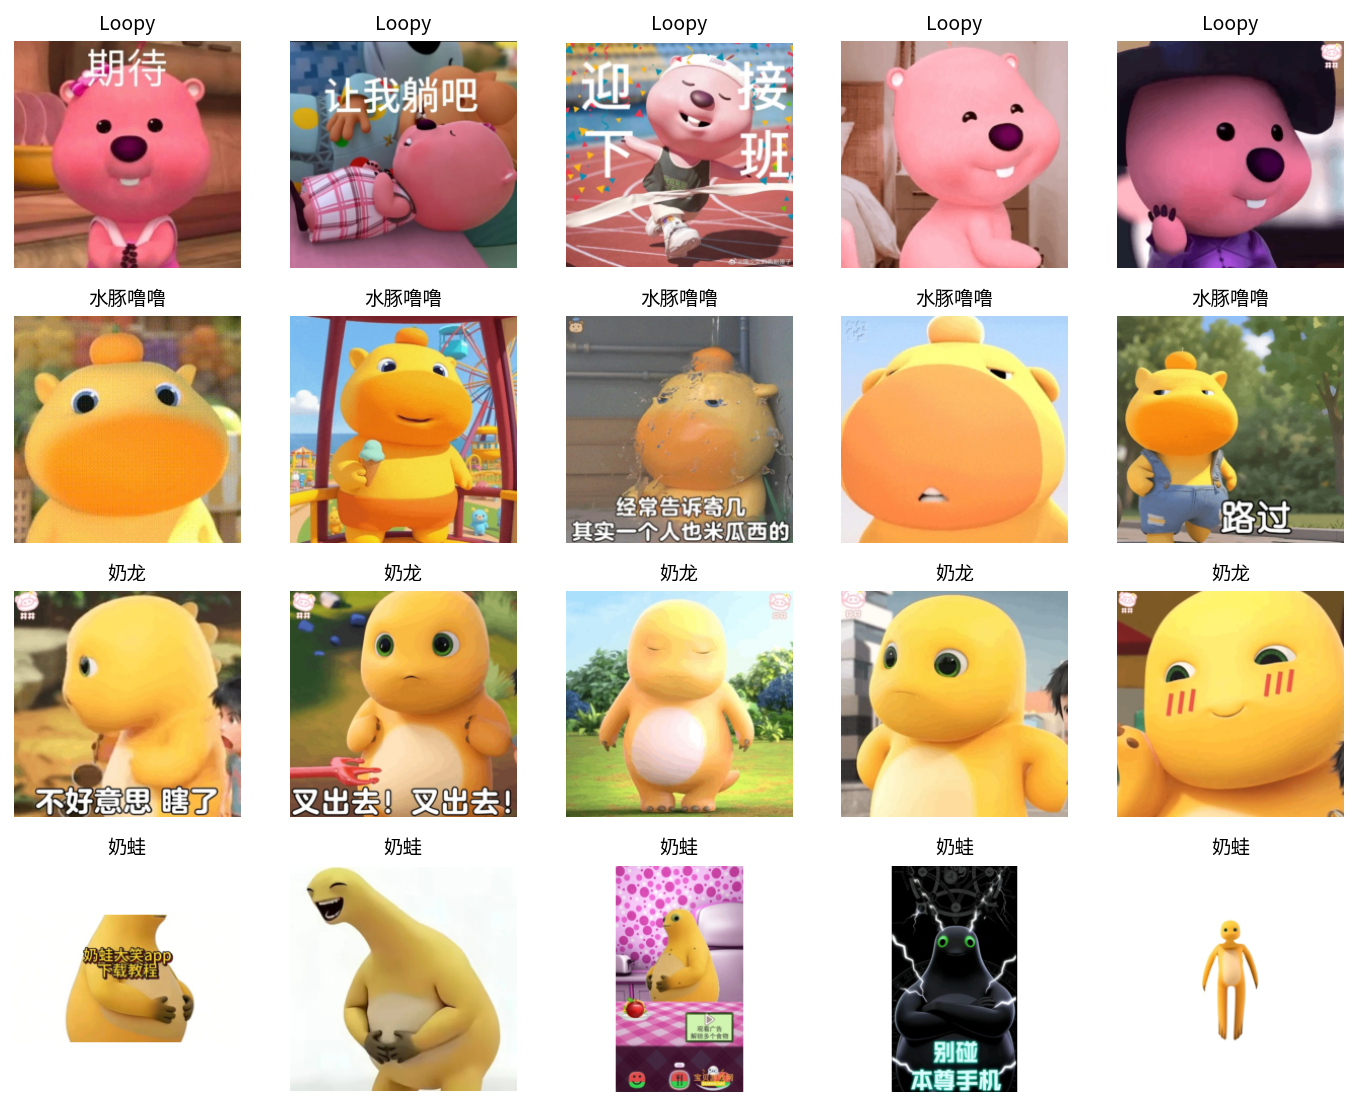

In [4]:
# 核对固定划分；摘要用于判断特征缓存和训练结果是否对应本次数据。
manifest = pd.read_csv(OUT / 'split_manifest.csv')
assert sorted(manifest['category'].unique()) == CLASSES
assert manifest.groupby('category').size().eq(250).all()
assert not manifest['sha256'].duplicated().any()
assert manifest.groupby('duplicate_group')['split'].nunique().max() == 1
DATA_ID = hashlib.sha256((OUT / 'split_manifest.csv').read_bytes()).hexdigest()
counts = pd.crosstab(manifest['category'], manifest['split']).reindex(CLASSES)
display(counts[['train', 'validation', 'test']])
print('总图片:', len(manifest), '| 跨集合重复组: 0')

# 按固定路径顺序读取图片与标签，使特征、预测和来源行保持对应。
def load_images(split, size=224):
    rows = manifest[manifest['split'] == split].sort_values(['category', 'path'])
    images = []
    for p in rows['path']:
        with Image.open(ROOT / p) as im:
            # 保持宽高比并白色补边，避免直接拉伸改变角色比例。
            im = ImageOps.pad(im.convert('RGB'), (size, size),
                              method=Image.Resampling.BILINEAR, color='white')
            images.append(np.asarray(im))
    # 将目录类别映射为0～3整数标签，适配稀疏交叉熵。
    y = rows['category'].map({c: i for i, c in enumerate(CLASSES)}).to_numpy('int32')
    return np.stack(images), y, rows.reset_index(drop=True)

# 本阶段只加载训练与验证集，测试图像在最终选模后读取。
x_train, y_train, train_rows = load_images('train')
x_val, y_val, val_rows = load_images('validation')
print('训练:', x_train.shape, '| 验证:', x_val.shape)
# 各展示5张训练图片，检查颜色、尺寸及类别是否符合预期。
fig, axes = plt.subplots(4, 5, figsize=(10, 8))
for i, name in enumerate(LABELS):
    indices = np.flatnonzero(y_train == i)[:5]
    for ax, index in zip(axes[i], indices):
        ax.imshow(x_train[index]); ax.set_title(name, fontsize=10); ax.axis('off')
plt.tight_layout(); plt.savefig(OUT / 'samples.png'); plt.show()

##### 2.2 模型与训练函数

CNN：128×128输入，Conv32→Pool→Conv64→Pool→Conv128→Pool→GAP→Dense128→Dropout→4类Softmax。预训练模型使用各自的官方预处理。

每轮记录完整训练集与验证集的Loss、Acc，评估时关闭增强和Dropout。验证Acc优先、相同时比较验证Loss，保存并恢复最佳权重；连续6轮未改进则早停，验证Loss停滞时降低学习率。

In [5]:
# 定义仅在training=True时生效的随机增强，验证和推理自动关闭。
def augmentation():
    # 小幅几何和对比度扰动；不改变角色颜色，不翻转表情文字。
    return keras.Sequential([
        layers.RandomRotation(0.025, fill_mode='constant', fill_value=255, seed=SEED),
        layers.RandomTranslation(0.06, 0.06, fill_mode='constant', fill_value=255, seed=SEED+1),
        layers.RandomZoom(0.1, fill_mode='constant', fill_value=255, seed=SEED+2),
        layers.RandomContrast(0.10, seed=SEED+3),
    ], name='augmentation')

# 基础CNN统一先缩放到128×128并除以255，再提取三组卷积特征。
def cnn_model(dropout=0.3, augment=False):
    inputs = keras.Input((224, 224, 3))
    x = augmentation()(inputs) if augment else inputs
    x = layers.Resizing(128, 128)(x)
    x = layers.Rescaling(1./255)(x)
    # 逐层增加通道并池化；末尾用全局平均池化减少分类头参数。
    for width in [32, 64, 128]:
        x = layers.Conv2D(width, 3, padding='same', activation='relu')(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu', name='head_dense')(x)
    x = layers.Dropout(dropout, name='head_dropout')(x)
    outputs = layers.Dense(4, activation='softmax', name='head_output')(x)
    return keras.Model(inputs, outputs, name='CNN')

# 冻结特征实验只训练128维隐藏层与四分类输出层。
def feature_head(dim, dropout=0.3):
    inputs = keras.Input((dim,))
    x = layers.Dense(128, activation='relu', name='head_dense')(inputs)
    x = layers.Dropout(dropout, name='head_dropout')(x)
    outputs = layers.Dense(4, activation='softmax', name='head_output')(x)
    return keras.Model(inputs, outputs)

# 创建原始ImageNet网络并加载用户提供的本地权重，不在线下载。
def pretrained(kind):
    if kind == 'vgg16':
        full = keras.applications.VGG16(weights=None, include_top=True)
    else:
        full = keras.applications.InceptionV3(weights=None, include_top=True)
    full.load_weights(str(next((ROOT / 'model').glob(kind + '*.h5'))))
    # 特征提取阶段冻结全部预训练参数，保留其通用视觉特征。
    full.trainable = False
    return full

# 使用已选中的分类头初始化微调模型，保留与冻结特征实验相同的池化结构。
def fine_vgg(config, head_checkpoint):
    full = pretrained('vgg16')
    base = keras.Model(full.input, full.get_layer('block5_pool').output, name='vgg16_base')
    base.trainable = True
    # 只允许最后一个卷积层block5_conv3更新，其他卷积层仍冻结。
    for layer in base.layers:
        layer.trainable = layer.name == 'block5_conv3'
    inputs = keras.Input((224, 224, 3))
    x = augmentation()(inputs)
    # 按VGG16官方方式转为BGR并减去ImageNet通道均值，不再除以255。
    x = keras.applications.vgg16.preprocess_input(x)
    x = base(x)
    x = layers.GlobalAveragePooling2D()(x)
    head = feature_head(512, config['dropout'])
    head.load_weights(str(head_checkpoint))
    outputs = head(x)
    return keras.Model(inputs, outputs, name='VGG16_last_conv')

In [6]:
# 汇总候选实验；配置版本与数据摘要共同控制是否可复用结果。
RUNS = {}
VERSION = 'ex4-four-characters-v1'

# 先写临时文件再替换，减少中断时留下不完整JSON的风险。
def save_json(path, value):
    temp = path.with_suffix('.tmp')
    temp.write_text(json.dumps(value, ensure_ascii=False, indent=2))
    temp.replace(path)

# 每轮记录完整指标；验证Acc优先，相同时选择验证Loss更低的权重。
class RecordBest(keras.callbacks.Callback):
    def __init__(self, name, train_x, train_y, checkpoint, patience=6):
        super().__init__()
        self.name, self.train_x, self.train_y = name, train_x, train_y
        self.checkpoint, self.patience = checkpoint, patience
        self.rows, self.best_key, self.wait, self.best_epoch = [], (-1., -float('inf')), 0, 0

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        # 与验证集一样关闭增强、Dropout，计算完整训练集指标。
        train_loss, train_acc = self.model.evaluate(self.train_x, self.train_y, batch_size=BATCH, verbose=0)
        row = {'Epoch': epoch+1, 'Train_Loss': float(train_loss), 'Train_Acc': float(train_acc),
               'Val_Loss': float(logs['val_loss']), 'Val_Acc': float(logs['val_accuracy']),
               'LR': float(keras.backend.get_value(self.model.optimizer.learning_rate))}
        self.rows.append(row)
        # 以同一规则更新最佳轮次；连续patience轮未改进时停止训练。
        key = (row['Val_Acc'], -row['Val_Loss'])
        if key > self.best_key:
            self.best_key, self.best_epoch, self.wait = key, epoch+1, 0
            self.model.save_weights(str(self.checkpoint))
        else:
            self.wait += 1
        pd.DataFrame(self.rows).to_csv(OUT / f'{self.name}_history.csv', index=False)
        print(f"{self.name} {epoch+1:02d}: train={train_acc:.3f}, val={row['Val_Acc']:.3f}, val_loss={row['Val_Loss']:.4f}", flush=True)
        if self.wait >= self.patience:
            self.model.stop_training = True

# 统一使用Adam和稀疏交叉熵；验证集只用于调度、早停和选模。
def run_fit(name, config, model, train_x, val_x):
    config = dict(config, seed=SEED, batch=BATCH, data_id=DATA_ID, version=VERSION)
    checkpoint = OUT / 'checkpoints' / f'{name}.weights.h5'
    record_path = OUT / f'{name}_run.json'
    model.compile(optimizer=keras.optimizers.Adam(config['lr']),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    # 仅在配置、种子和数据摘要完全一致时加载原实测权重与历史。
    if record_path.exists() and checkpoint.exists():
        result = json.loads(record_path.read_text())
        if result['config'] == config:
            model.load_weights(str(checkpoint))
            RUNS[name] = result
            print(name, '复用已核对配置的结果:', result['val_acc'])
            return result
    # 启动训练并计时；验证Loss连续3轮停滞时将学习率减半。
    callback = RecordBest(name, train_x, y_train, checkpoint)
    start = time.perf_counter()
    model.fit(train_x, y_train, validation_data=(val_x, y_val), batch_size=BATCH,
              epochs=config['epochs'], shuffle=True, verbose=0, callbacks=[callback,
              keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3,
                                              min_lr=config['lr']/16, verbose=0)])
    model.load_weights(str(checkpoint))
    # 此时已恢复最佳验证轮次；结果表读取相应轮次指标，测试使用同一权重。
    best = callback.rows[callback.best_epoch-1]
    result = dict(name=name, config=config, best_epoch=callback.best_epoch,
                  train_acc=best['Train_Acc'], train_loss=best['Train_Loss'],
                  val_acc=best['Val_Acc'], val_loss=best['Val_Loss'],
                  seconds=time.perf_counter()-start, parameters=int(model.count_params()),
                  trainable_parameters=int(sum(np.prod(v.shape) for v in model.trainable_weights)),
                  checkpoint=str(checkpoint.relative_to(ROOT)))
    save_json(record_path, result)
    RUNS[name] = result
    return result

# 所有候选统一按验证Acc降序、验证Loss升序排列。
def rank_names(names):
    return sorted(names, key=lambda n: (-RUNS[n]['val_acc'], RUNS[n]['val_loss']))

# 展示验证指标、可训练参数量和训练耗时，供方法比较。
def validation_table(names):
    frame = pd.DataFrame([RUNS[n] for n in rank_names(names)])
    display(frame[['name','best_epoch','train_acc','val_acc','val_loss','trainable_parameters','seconds']].round(4))

# 成对绘制训练／验证Loss与Acc，检查收敛速度及泛化差距。
def plot_history(names, filename):
    fig, axes = plt.subplots(len(names), 2, figsize=(11, 2.7*len(names)), squeeze=False)
    for row, name in enumerate(names):
        h = pd.read_csv(OUT / f'{name}_history.csv')
        for ax, metric in zip(axes[row], ['Loss','Acc']):
            ax.plot(h.Epoch, h[f'Train_{metric}'], label='Train')
            ax.plot(h.Epoch, h[f'Val_{metric}'], label='Validation', linestyle='--')
            ax.set(title=f'{name}: {metric}', xlabel='Epoch')
            ax.grid(alpha=.25); ax.legend(fontsize=8)
    plt.tight_layout(); plt.savefig(OUT / filename); plt.show()

##### 2.3 CNN基线、增强与针对性调参

| 对照 | 学习率 | Dropout | 训练增强 | 最多轮数 |
| :--- | ---: | ---: | :---: | ---: |
| 基线 | 1e-3 | 0.3 | 否 | 30 |
| 只加增强 | 1e-3 | 0.3 | 是 | 30 |
| 降低学习率 | 3e-4 | 0.3 | 是 | 30 |
| 增加Dropout | 1e-3 | 0.5 | 是 | 30 |

增强采用小幅旋转、平移、缩放和对比度扰动；不改变角色颜色，不水平翻转表情文字。前两组隔离增强的影响，后两组分别检查更新步长和过拟合，不做全组合遍历。

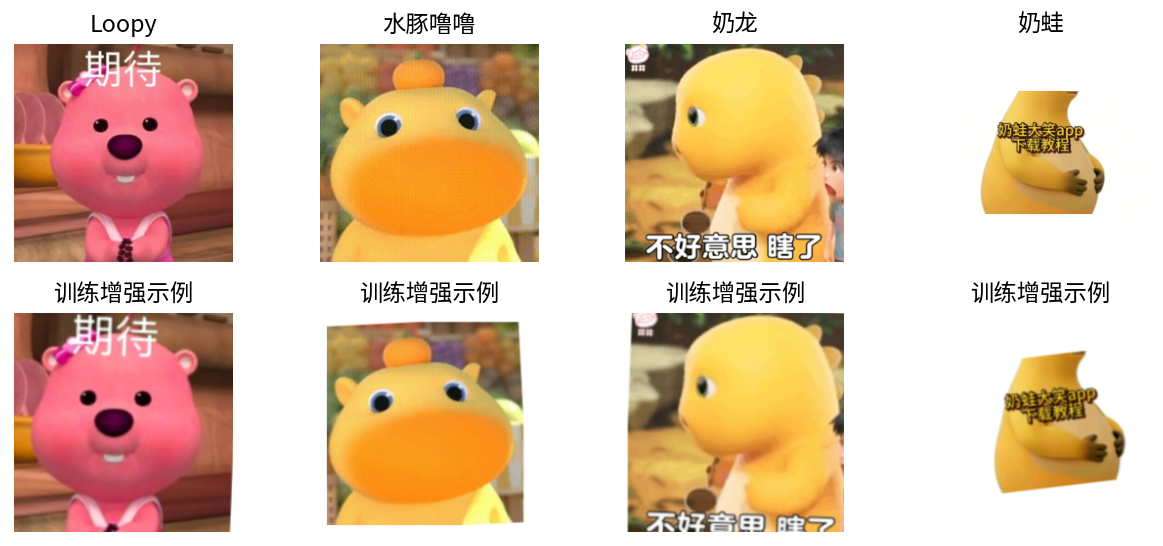

In [7]:
# 从四类训练集各取一张图，固定随机状态后展示增强前后的对照。
set_seed()
indices = [np.flatnonzero(y_train==i)[0] for i in range(4)]
example = x_train[indices]
# 显式启用训练模式生成示例；不会修改原始图片或增加独立样本数。
augmented = augmentation()(example, training=True).numpy()
# 上排为原图，下排为相应增强结果；显示前裁剪像素范围。
fig, axes = plt.subplots(2,4,figsize=(9,4))
for i in range(4):
    axes[0,i].imshow(example[i]); axes[0,i].set_title(LABELS[i])
    axes[1,i].imshow(np.clip(augmented[i],0,255).astype('uint8'))
    axes[1,i].set_title('训练增强示例')
for ax in axes.flat: ax.axis('off')
plt.tight_layout(); plt.savefig(OUT/'augmentation_examples.png'); plt.show()

CNN_baseline 复用已核对配置的结果: 0.8648648858070374


CNN_augmentation 复用已核对配置的结果: 0.8445945978164673


CNN_lower_lr 复用已核对配置的结果: 0.8108108043670654


CNN_more_dropout 复用已核对配置的结果: 0.8445945978164673


,name,best_epoch,train_acc,val_acc,val_loss,trainable_parameters,seconds
0,CNN_baseline,30,0.9100,0.8649,0.3832,110276,8.0440
1,CNN_augmentation,15,0.8371,0.8446,0.4398,110276,28.3848
2,CNN_more_dropout,19,0.8671,0.8446,0.4650,110276,33.7589
3,CNN_lower_lr,30,0.8414,0.8108,0.4760,110276,39.8301


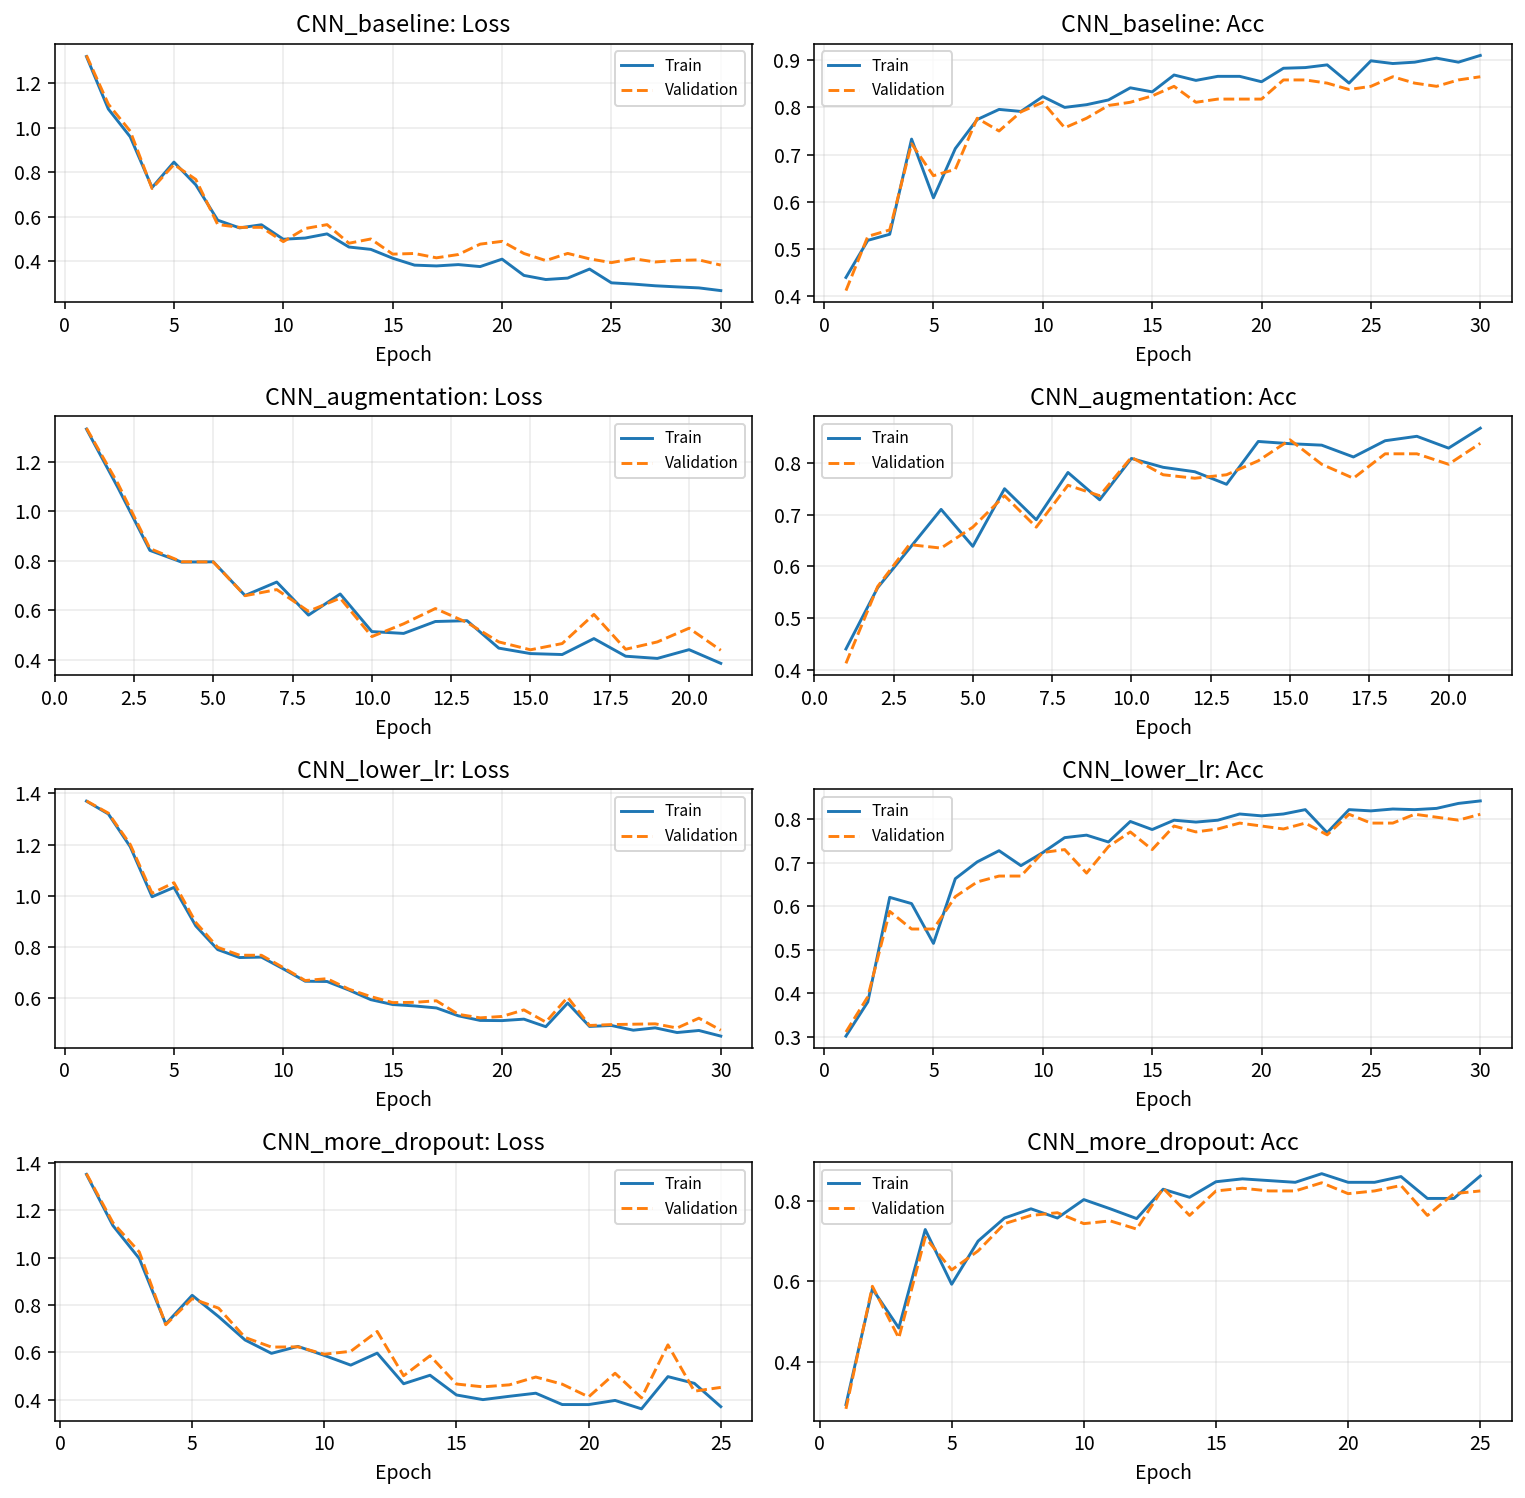

82401

In [8]:
# 先做增强对照，再分别调整学习率和Dropout，不做全组合搜索。
cnn_configs = {
 'CNN_baseline': dict(kind='cnn', lr=1e-3, dropout=0.3, augment=False, epochs=30),
 'CNN_augmentation': dict(kind='cnn', lr=1e-3, dropout=0.3, augment=True, epochs=30),
 'CNN_lower_lr': dict(kind='cnn', lr=3e-4, dropout=0.3, augment=True, epochs=30),
 'CNN_more_dropout': dict(kind='cnn', lr=1e-3, dropout=0.5, augment=True, epochs=30),
}
# 每组重新建模并重置种子；四组共享同一训练、验证划分。
for name, config in cnn_configs.items():
    keras.backend.clear_session(); gc.collect(); set_seed()
    model = cnn_model(config['dropout'], config['augment'])
    run_fit(name, config, model, x_train, x_val)
# 结合验证指标与学习曲线比较增强、学习率和Dropout的作用。
validation_table(cnn_configs)
plot_history(list(cnn_configs), 'cnn_curves.png')
del model; keras.backend.clear_session(); gc.collect()

#### 三、直接使用预训练VGG16

原VGG16的层、权重及1000类ImageNet分类头均不修改。原始类别没有奶龙等四个标签，不能将1000类输出编号直接与四类编号比较。

先展示原始输出，再仅用训练集计算`P(本实验类别 | ImageNet类别)`，将原输出概率映射为四类。此步骤不训练神经网络，但引入训练集统计后处理；表中单独命名为`VGG16_original_mapped`，不将其误称为原模型自带的四分类能力。

In [9]:
# 冻结骨干提取特征，同时保留原1000类概率；缓存使用数据摘要校验。
def extract_features(kind, split, images=None):
    # 测试特征只在选模完成之后调用本函数计算。
    cache = OUT / f'{kind}_{split}_features.npz'
    if cache.exists():
        with np.load(cache) as data:
            if str(data['data_id']) == DATA_ID:
                return data['features'], data['probabilities']
    # VGG16使用224×224输入，InceptionV3使用299×299输入。
    if images is None:
        images, _, _ = load_images(split, 224 if kind == 'vgg16' else 299)
    elif kind == 'inception_v3':
        images, _, _ = load_images(split, 299)
    keras.backend.clear_session(); gc.collect(); set_seed()
    full = pretrained(kind)
    # VGG16取末次池化后的512维GAP特征，InceptionV3取2048维特征。
    if kind == 'vgg16':
        features = layers.GlobalAveragePooling2D()(full.get_layer('block5_pool').output)
        preprocess = keras.applications.vgg16.preprocess_input
    else:
        features = full.get_layer('avg_pool').output
        preprocess = keras.applications.inception_v3.preprocess_input
    extractor = keras.Model(full.input, [features, full.output])
    values, probabilities = [], []
    start = time.perf_counter()
    # 分批执行对应骨干的官方预处理，关闭训练模式，不更新权重。
    for i in range(0, len(images), BATCH):
        x = preprocess(images[i:i+BATCH].astype('float32'))
        f, p = extractor(x, training=False)
        values.append(f.numpy()); probabilities.append(p.numpy())
    values, probabilities = np.concatenate(values), np.concatenate(probabilities)
    # 分别保存特征、原类别概率与提取耗时；分类头训练时间另行统计。
    np.savez_compressed(cache, features=values, probabilities=probabilities, data_id=DATA_ID,
                        extraction_seconds=time.perf_counter()-start)
    print(kind, split, values.shape, '提取秒数:', round(time.perf_counter()-start, 2))
    del full, extractor; keras.backend.clear_session(); gc.collect()
    return values, probabilities

# 此处只提取训练与验证特征，测试特征在选模后计算。
vgg_train, vgg_p_train = extract_features('vgg16', 'train', x_train)
vgg_val, vgg_p_val = extract_features('vgg16', 'validation', x_val)

In [10]:
# 原VGG16仍输出1000个ImageNet类别，所有权重和层保持不变。
# 仅用训练集建立ImageNet输出到四类的概率映射，用于报告可比较的四分类指标。
onehot = np.eye(4, dtype='float32')[y_train]
# 累加训练集中各ImageNet输出对四类的概率质量，并加平滑项后归一化。
class_map = vgg_p_train.T @ onehot + 1e-3
class_map /= class_map.sum(axis=1, keepdims=True)
np.save(OUT / 'vgg16_imagenet_class_map.npy', class_map)

# 原网络输出与统计映射相乘得到四类概率；映射不读取验证或测试标签。
def mapped_probabilities(probabilities):
    output = probabilities @ class_map
    return output / output.sum(axis=1, keepdims=True)

# 按真实类别读取概率并取负对数；截断极小值，避免log(0)。
def cross_entropy(y, p):
    return float(-np.log(np.maximum(p[np.arange(len(y)), y], 1e-7)).mean())

direct_train, direct_val = mapped_probabilities(vgg_p_train), mapped_probabilities(vgg_p_val)
# 单独记录原网络加统计后处理的结果，可训练网络参数数目为0。
RUNS['VGG16_original_mapped'] = dict(
    name='VGG16_original_mapped', config={'kind':'direct','data_id':DATA_ID}, best_epoch=0,
    train_acc=float(accuracy_score(y_train, direct_train.argmax(1))),
    train_loss=cross_entropy(y_train,direct_train),
    val_acc=float(accuracy_score(y_val,direct_val.argmax(1))),
    val_loss=cross_entropy(y_val,direct_val), seconds=0., parameters=138357544,
    trainable_parameters=0, checkpoint=None)
display(pd.DataFrame({'真实类别':[LABELS[i] for i in y_val[:8]],
                     '原ImageNet输出编号':vgg_p_val[:8].argmax(1),
                     '原输出置信度':vgg_p_val[:8].max(1),
                     '映射后四分类':[LABELS[i] for i in direct_val[:8].argmax(1)]}))
validation_table(['VGG16_original_mapped'])

,真实类别,原ImageNet输出编号,原输出置信度,映射后四分类
0,Loopy,719,0.423414,Loopy
1,Loopy,719,0.408959,Loopy
2,Loopy,719,0.631553,Loopy
3,Loopy,719,0.929430,Loopy
4,Loopy,719,0.589096,Loopy
5,Loopy,719,0.621236,Loopy
6,Loopy,719,0.984479,Loopy
7,Loopy,804,0.112290,Loopy


,name,best_epoch,train_acc,val_acc,val_loss,trainable_parameters,seconds
0,VGG16_original_mapped,0,0.7443,0.75,1.1065,0,0.0


#### 四、VGG16特征提取

冻结全部卷积层，block5_pool后全局平均池化得到512维特征，只训练128→4分类头。特征提取一次后缓存，减少重复计算。

比较三组：学习率1e-3、Dropout0.3；只将学习率降为3e-4；只将Dropout提高为0.5。每组最多35轮，按验证集选出后续微调的起点。

VGG16_features 复用已核对配置的结果: 0.9527027010917664
VGG16_features_lower_lr 复用已核对配置的结果: 0.9391891956329346
VGG16_features_more_dropout 复用已核对配置的结果: 0.9459459185600281


,name,best_epoch,train_acc,val_acc,val_loss,trainable_parameters,seconds
0,VGG16_features,13,1.0000,0.9527,0.1874,66180,1.2434
1,VGG16_features_more_dropout,10,0.9986,0.9459,0.2569,66180,1.0996
2,VGG16_features_lower_lr,22,1.0000,0.9392,0.2640,66180,1.7323


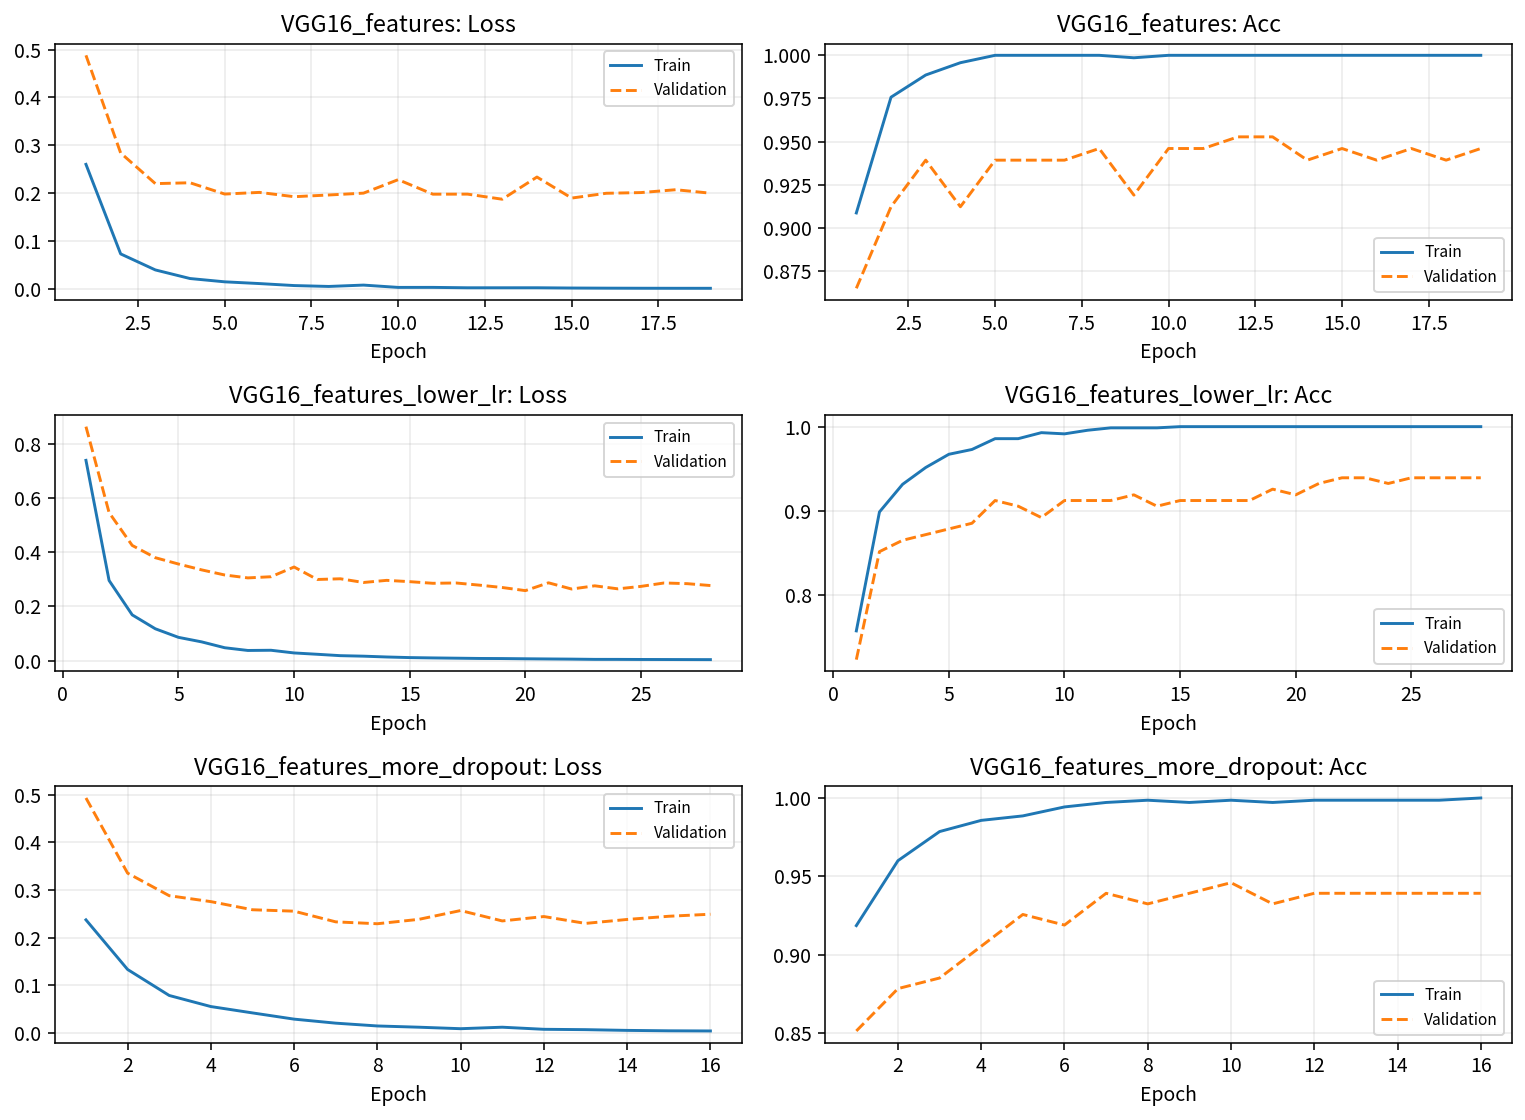

仅按验证集选出的冻结特征分类器: VGG16_features


In [11]:
# 固定512维骨干特征，分别只调整分类头学习率或Dropout。
vgg_configs = {
 'VGG16_features': dict(kind='vgg_head', lr=1e-3, dropout=0.3, epochs=35),
 'VGG16_features_lower_lr': dict(kind='vgg_head', lr=3e-4, dropout=0.3, epochs=35),
 'VGG16_features_more_dropout': dict(kind='vgg_head', lr=1e-3, dropout=0.5, epochs=35),
}
# 每组分类头独立初始化；骨干特征直接复用，无需重复前向传播。
for name, config in vgg_configs.items():
    keras.backend.clear_session(); gc.collect(); set_seed()
    model = feature_head(512, config['dropout'])
    run_fit(name, config, model, vgg_train, vgg_val)
    # 总参数量计入冻结的VGG16骨干，可训练参数只计算分类头。
    RUNS[name]['parameters'] = int(14714688 + model.count_params())
validation_table(vgg_configs)
plot_history(list(vgg_configs), 'vgg_feature_curves.png')
# 仅按验证指标选择分类头，保存其路径与Dropout供后续微调初始化。
best_vgg_head = rank_names(vgg_configs)[0]
head_checkpoint = ROOT / RUNS[best_vgg_head]['checkpoint']
head_dropout = RUNS[best_vgg_head]['config']['dropout']
del model; keras.backend.clear_session(); gc.collect()
print('仅按验证集选出的冻结特征分类器:', best_vgg_head)

#### 五、微调最后一层卷积

加载验证集选中的分类头，仅解冻`block5_conv3`；其他卷积层保持冻结。保留原池化和分类头结构，训练集使用前述增强，分别比较1e-5与3e-5两个小学习率，每组最多20轮。

可训练卷积层: ['block5_conv3']
VGG16_last_conv_1e5 复用已核对配置的结果: 0.9662162065505981


可训练卷积层: ['block5_conv3']
VGG16_last_conv_3e5 复用已核对配置的结果: 0.9594594836235046


,name,best_epoch,train_acc,val_acc,val_loss,trainable_parameters,seconds
0,VGG16_last_conv_1e5,13,1.0,0.9662,0.2049,2425988,54.2126
1,VGG16_last_conv_3e5,2,1.0,0.9595,0.1858,2425988,22.3797


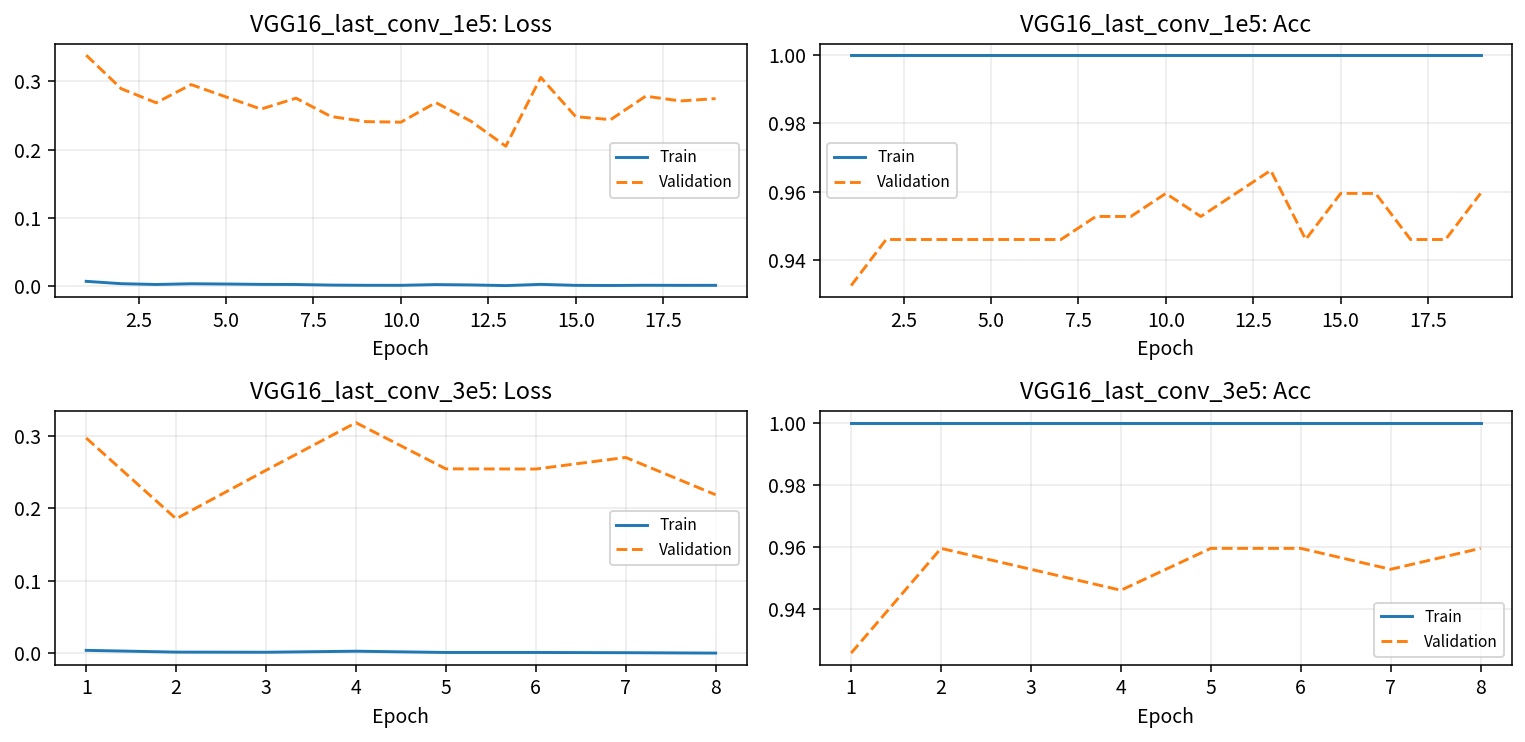

70776

In [12]:
# 从同一最佳分类头出发，比较1e-5与3e-5两个较小微调学习率。
fine_configs = {
 'VGG16_last_conv_1e5': dict(kind='vgg_fine', lr=1e-5, dropout=head_dropout, epochs=20, head=best_vgg_head),
 'VGG16_last_conv_3e5': dict(kind='vgg_fine', lr=3e-5, dropout=head_dropout, epochs=20, head=best_vgg_head),
}
# 每次重新加载原骨干及选中分类头，避免继承上一组微调权重。
for name, config in fine_configs.items():
    keras.backend.clear_session(); gc.collect(); set_seed()
    model = fine_vgg(config, head_checkpoint)
    conv_names = [l.name for l in model.get_layer('vgg16_base').layers
                  if isinstance(l, layers.Conv2D) and l.trainable]
    # 显式核对可训练卷积层，确保没有意外解冻整个VGG16。
    assert conv_names == ['block5_conv3']
    print('可训练卷积层:', conv_names)
    run_fit(name, config, model, x_train, x_val)
# 按验证集比较两个学习率，并观察微调是否缩小泛化差距。
validation_table(fine_configs)
plot_history(list(fine_configs), 'vgg_finetune_curves.png')
del model; keras.backend.clear_session(); gc.collect()

#### 六、更换InceptionV3及独立测试
##### 6.1 InceptionV3特征提取

加载本地InceptionV3权重，以299×299输入提取2048维特征；仍使用128→4分类头，比较1e-3与3e-4两个学习率，最多35轮。输入尺寸与骨干不同，训练耗时和参数量一并记录。

InceptionV3_features 复用已核对配置的结果: 0.9391891956329346
InceptionV3_features_lower_lr 复用已核对配置的结果: 0.9391891956329346


,name,best_epoch,train_acc,val_acc,val_loss,trainable_parameters,seconds
0,InceptionV3_features_lower_lr,33,1.0,0.9392,0.2053,262788,2.2312
1,InceptionV3_features,11,1.0,0.9392,0.2114,262788,1.1666


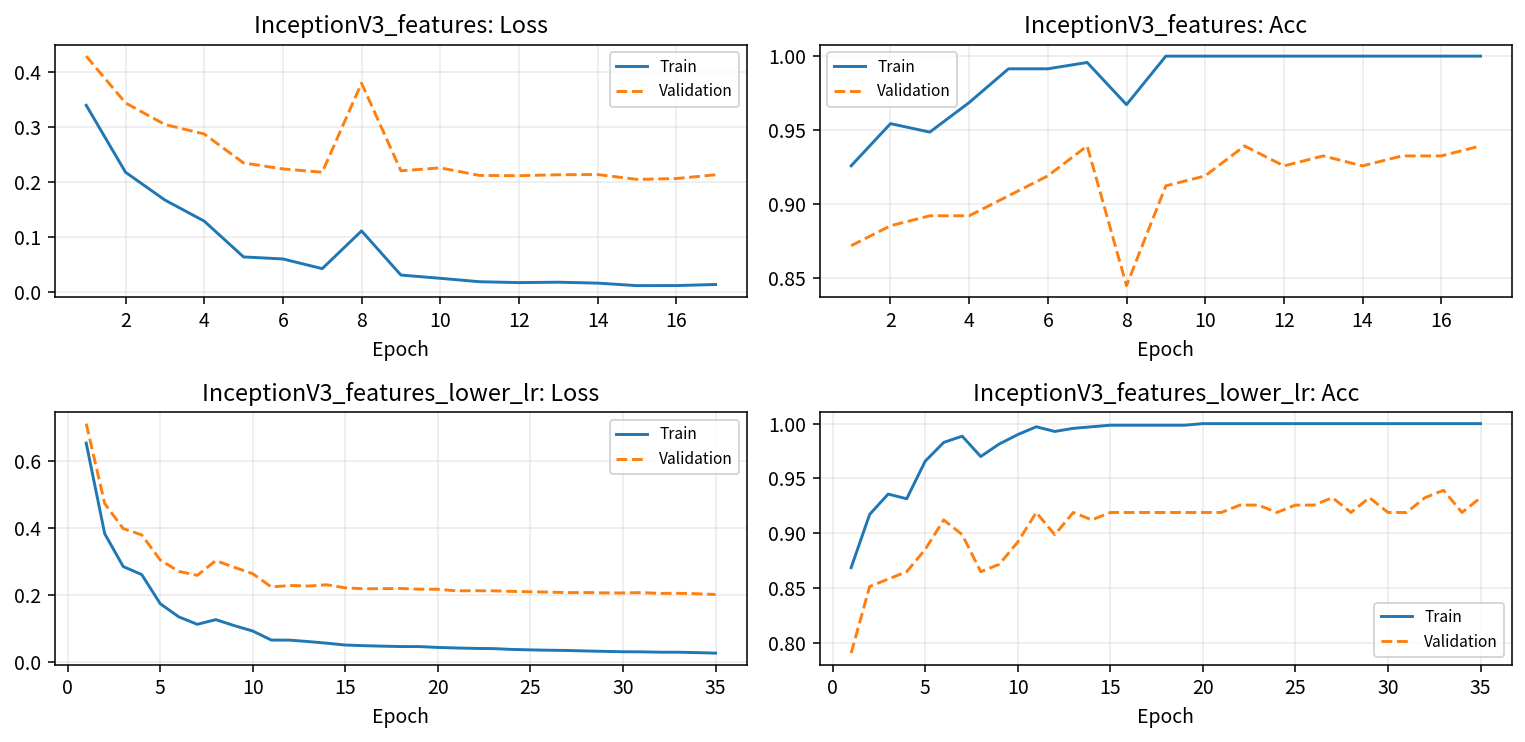

15535

In [13]:
# 提取InceptionV3的2048维训练／验证特征，使用其官方输入尺寸。
inc_train, _ = extract_features('inception_v3', 'train')
inc_val, _ = extract_features('inception_v3', 'validation')
# 保持相同分类头宽度与Dropout，仅比较两个学习率。
inc_configs = {
 'InceptionV3_features': dict(kind='inc_head', lr=1e-3, dropout=0.3, epochs=35),
 'InceptionV3_features_lower_lr': dict(kind='inc_head', lr=3e-4, dropout=0.3, epochs=35),
}
# 重置随机状态并独立训练分类头；InceptionV3骨干始终冻结。
for name, config in inc_configs.items():
    keras.backend.clear_session(); gc.collect(); set_seed()
    model = feature_head(2048, config['dropout'])
    run_fit(name, config, model, inc_train, inc_val)
    # 总参数量包含骨干；训练时间仅包含分类头拟合，提取时间另存。
    RUNS[name]['parameters'] = int(21802784 + model.count_params())
validation_table(inc_configs)
plot_history(list(inc_configs), 'inception_curves.png')
del model; keras.backend.clear_session(); gc.collect()

##### 6.2 验证集选模与统一测试

先固定最终模型并保存`selection_before_test.json`，再对所有方法统一测试。总计11次训练加1个原VGG16输出映射对照；测试指标只用于最终比较。

训练秒数按实际拟合记录；缓存特征方法的骨干提取时间另存于特征文件，不与端到端模型的训练耗时直接作倍数比较。

In [14]:
# 在第一次测试预测之前，落盘保存全部候选、验证指标和最终选择。
# 此处只读取验证指标；第一次测试之前将最终选择及所有候选配置落盘。
selected = rank_names(RUNS)[0]
selection = {'selected':selected, 'criterion':'val_acc descending, val_loss ascending',
             'data_id':DATA_ID, 'test_used_for_selection':False, 'runs':RUNS}
save_json(OUT / 'selection_before_test.json', selection)
validation_table(RUNS)
print('最终模型:', selected)

,name,best_epoch,train_acc,val_acc,val_loss,trainable_parameters,seconds
0,VGG16_last_conv_1e5,13,1.0000,0.9662,0.2049,2425988,54.2126
1,VGG16_last_conv_3e5,2,1.0000,0.9595,0.1858,2425988,22.3797
2,VGG16_features,13,1.0000,0.9527,0.1874,66180,1.2434
3,VGG16_features_more_dropout,10,0.9986,0.9459,0.2569,66180,1.0996
4,InceptionV3_features_lower_lr,33,1.0000,0.9392,0.2053,262788,2.2312
5,InceptionV3_features,11,1.0000,0.9392,0.2114,262788,1.1666
6,VGG16_features_lower_lr,22,1.0000,0.9392,0.2640,66180,1.7323
7,CNN_baseline,30,0.9100,0.8649,0.3832,110276,8.0440
8,CNN_augmentation,15,0.8371,0.8446,0.4398,110276,28.3848
9,CNN_more_dropout,19,0.8671,0.8446,0.4650,110276,33.7589


最终模型: VGG16_last_conv_1e5


In [15]:
# 模型选择已固定，现在才加载测试图像并准备两种冻结骨干特征。
x_test, y_test, test_rows = load_images('test')
vgg_test, vgg_p_test = extract_features('vgg16', 'test', x_test)
inc_test, _ = extract_features('inception_v3', 'test')
test_results, predictions = [], {}
# 按训练时配置重建候选模型，统一用最佳验证权重计算独立测试预测。
for name, result in RUNS.items():
    kind, cfg = result['config']['kind'], result['config']
    keras.backend.clear_session(); gc.collect(); set_seed()
    start = time.perf_counter()
    # 原VGG16映射对照只应用训练集学到的概率映射，不再更新参数。
    if kind == 'direct':
        probabilities = mapped_probabilities(vgg_p_test)
    else:
        if kind == 'cnn':
            model = cnn_model(cfg['dropout'], cfg['augment']); test_x = x_test
        elif kind in ['vgg_head','inc_head']:
            model = feature_head(512 if kind=='vgg_head' else 2048, cfg['dropout'])
            test_x = vgg_test if kind=='vgg_head' else inc_test
        else:
            model = fine_vgg(cfg, ROOT / RUNS[cfg['head']]['checkpoint']); test_x = x_test
        # 加载所选轮次权重；predict自动关闭Dropout和随机增强。
        model.load_weights(str(ROOT / result['checkpoint']))
        probabilities = model.predict(test_x, batch_size=BATCH, verbose=0)
        del model
    # 以最大概率类别作为预测，保存逐图概率用于复核与错误分析。
    prediction = probabilities.argmax(1)
    predictions[name] = probabilities
    np.save(OUT / f'{name}_test_probabilities.npy', probabilities)
    row = {k:result[k] for k in ['name','best_epoch','train_acc','val_acc','val_loss','parameters','trainable_parameters','seconds']}
    # 同时记录交叉熵、总体准确率和宏平均F1，避免只看单一指标。
    row.update(test_loss=cross_entropy(y_test,probabilities),
               test_acc=float(accuracy_score(y_test,prediction)),
               macro_f1=float(f1_score(y_test,prediction,average='macro')))
    test_results.append(row)
# 结果表仍按验证指标排序，测试得分不会反过来改变最终模型。
results = pd.DataFrame(test_results).sort_values(['val_acc','val_loss'],ascending=[False,True])
results.to_csv(OUT / 'results.csv', index=False)
save_json(OUT / 'results.json', test_results)
display(results.round(4))

,name,best_epoch,train_acc,val_acc,val_loss,parameters,trainable_parameters,seconds,test_loss,test_acc,macro_f1
8,VGG16_last_conv_1e5,13,1.0000,0.9662,0.2049,14780868,2425988,54.2126,0.1078,0.9671,0.9668
9,VGG16_last_conv_3e5,2,1.0000,0.9595,0.1858,14780868,2425988,22.3797,0.1171,0.9539,0.9537
5,VGG16_features,13,1.0000,0.9527,0.1874,14780868,66180,1.2434,0.1193,0.9539,0.9534
7,VGG16_features_more_dropout,10,0.9986,0.9459,0.2569,14780868,66180,1.0996,0.1550,0.9539,0.9537
11,InceptionV3_features_lower_lr,33,1.0000,0.9392,0.2053,22065572,262788,2.2312,0.1946,0.9211,0.9218
10,InceptionV3_features,11,1.0000,0.9392,0.2114,22065572,262788,1.1666,0.2068,0.9276,0.9283
6,VGG16_features_lower_lr,22,1.0000,0.9392,0.2640,14780868,66180,1.7323,0.1378,0.9474,0.9469
0,CNN_baseline,30,0.9100,0.8649,0.3832,110276,110276,8.0440,0.3617,0.8618,0.8618
1,CNN_augmentation,15,0.8371,0.8446,0.4398,110276,110276,28.3848,0.5576,0.8421,0.8412
3,CNN_more_dropout,19,0.8671,0.8446,0.4650,110276,110276,33.7589,0.5298,0.8224,0.8193


##### 6.3 类别表现与预测检查

对验证集选中的模型绘制混淆矩阵、分类报告及预测示例，优先展示误分类图片。

,precision,recall,f1-score,support
Loopy,0.9744,1.0000,0.9870,38.0000
水豚噜噜,0.9737,0.9737,0.9737,38.0000
奶龙,0.9268,1.0000,0.9620,38.0000
奶蛙,1.0000,0.8947,0.9444,38.0000
accuracy,0.9671,0.9671,0.9671,0.9671
macro avg,0.9687,0.9671,0.9668,152.0000
weighted avg,0.9687,0.9671,0.9668,152.0000


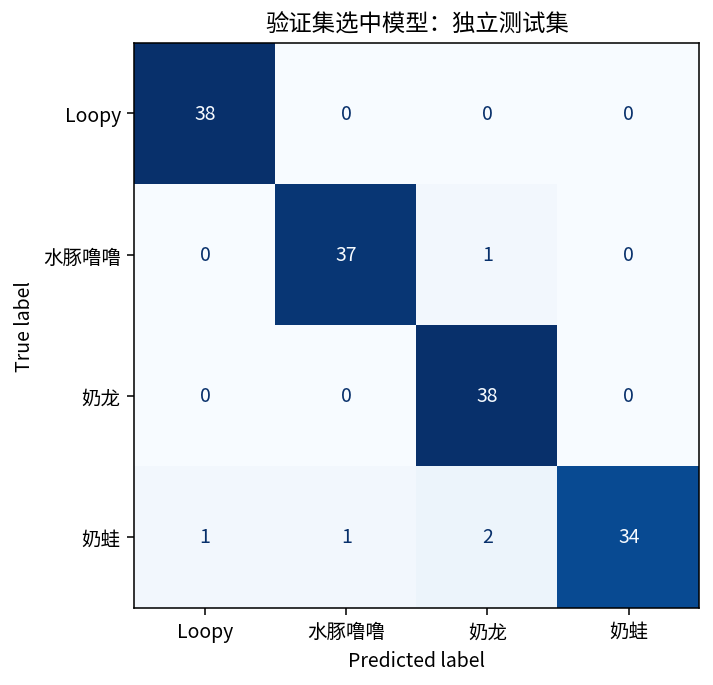

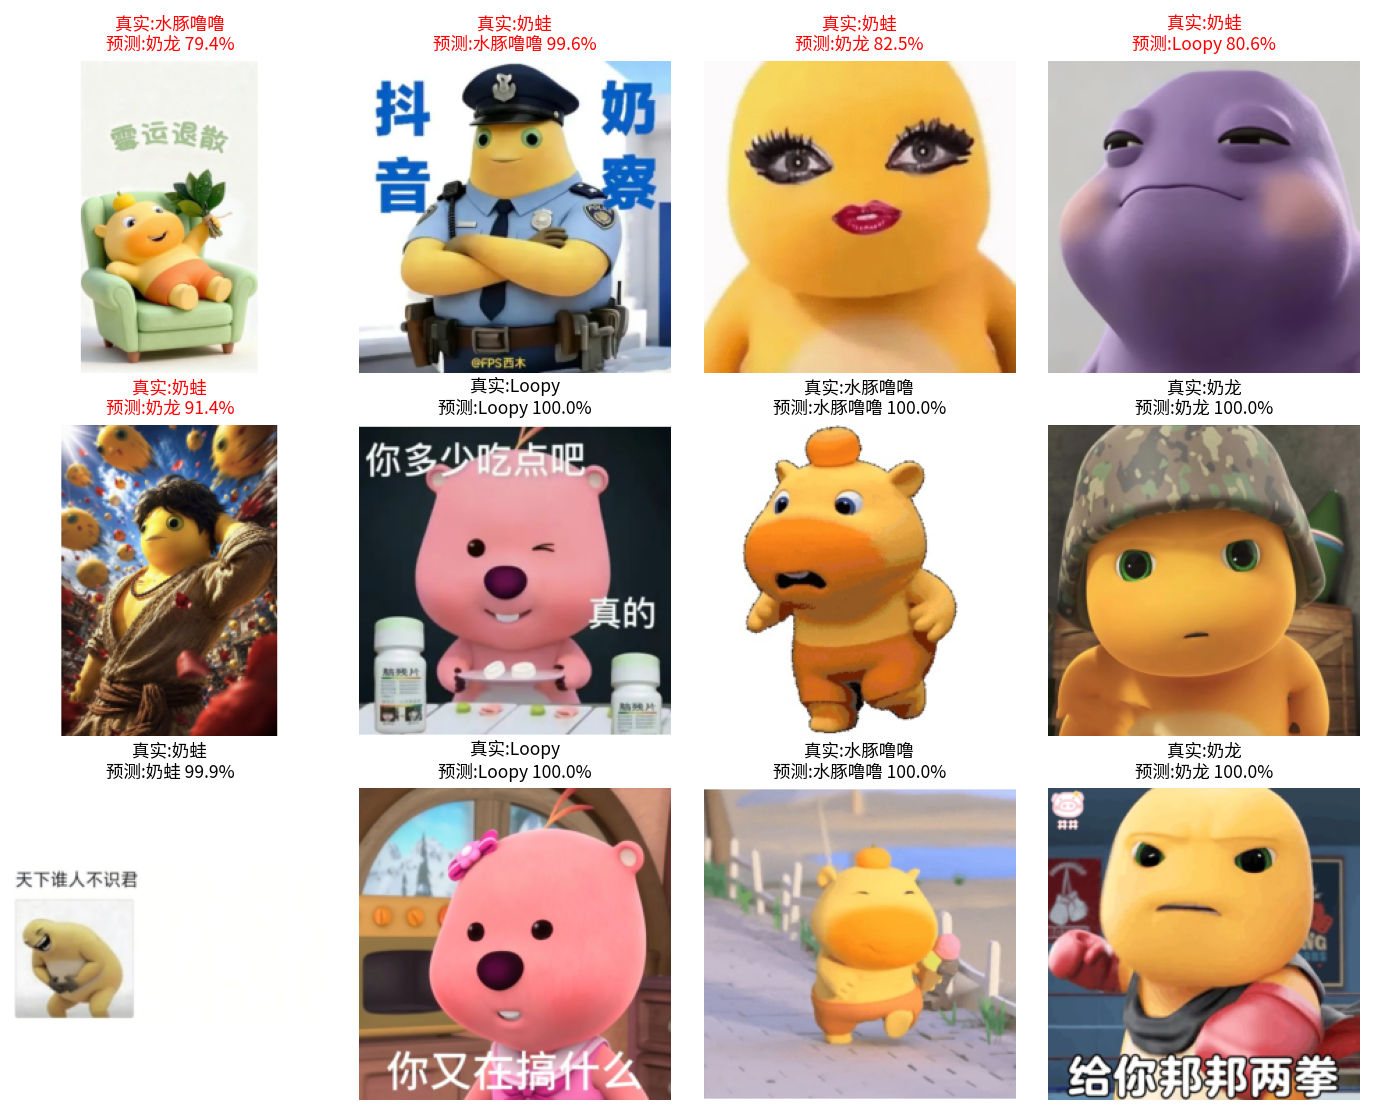

In [16]:
# 只对验证集选中的最终模型展开类别分析，不按测试集重新挑模型。
winner_p = predictions[selected]
winner_y = winner_p.argmax(1)
# 按类别统计Precision、Recall和F1，并保存混淆矩阵。
report = classification_report(y_test, winner_y, target_names=LABELS, output_dict=True, zero_division=0)
display(pd.DataFrame(report).T.round(4))
save_json(OUT / 'classification_report.json', report)
fig, ax = plt.subplots(figsize=(6,5))
ConfusionMatrixDisplay.from_predictions(y_test,winner_y,display_labels=LABELS,cmap='Blues',ax=ax,colorbar=False)
ax.set_title('验证集选中模型：独立测试集'); plt.tight_layout()
plt.savefig(OUT / 'confusion_matrix.png'); plt.show()
# 优先展示误分类，再从各类轮流补充正确示例，避免只展示容易样本。
wrong = np.flatnonzero(winner_y != y_test)
correct_by_class = [np.flatnonzero((y_test==c) & (winner_y==y_test)).tolist() for c in range(4)]
balanced_correct = [group[j] for j in range(12) for group in correct_by_class if len(group)>j]
indices = list(wrong[:8]) + balanced_correct[:max(0,12-min(8,len(wrong)))]
# 标题标出真实类别、预测类别与置信度，误分类用红色标记。
fig, axes = plt.subplots(3,4,figsize=(10,8))
for ax,index in zip(axes.flat,indices):
    ax.imshow(x_test[index]); ax.axis('off')
    ax.set_title(f'真实:{LABELS[y_test[index]]}\n预测:{LABELS[winner_y[index]]} {winner_p[index].max():.1%}',
                 color='red' if winner_y[index]!=y_test[index] else 'black',fontsize=9)
for ax in list(axes.flat)[len(indices):]: ax.axis('off')
plt.tight_layout(); plt.savefig(OUT / 'predictions.png'); plt.show()
# 保存原图片路径与逐图预测，测试正确数可由该表独立重算。
prediction_table = test_rows[['path','category']].copy()
prediction_table['predicted'] = [CLASSES[i] for i in winner_y]
prediction_table['confidence'] = winner_p.max(1)
prediction_table.to_csv(OUT / 'test_predictions.csv', index=False)

##### 6.4 保存与重载

保存最佳权重、类别顺序、结构配置和预处理信息；重新加载后检查预测一致。

In [17]:
# 保存最终权重、类别顺序及输入约定，保证后续推理与训练保持一致。
import shutil
chosen = RUNS[selected]
export = OUT / 'final_model'
export.mkdir(exist_ok=True)
if chosen['checkpoint']:
    shutil.copy2(ROOT / chosen['checkpoint'], export / 'best.weights.h5')
else:
    shutil.copy2(OUT / 'vgg16_imagenet_class_map.npy', export / 'class_map.npy')
# 元数据记录结构配置和数据摘要，避免拿错类别顺序或预处理方式。
metadata = {'selected':selected,'config':chosen['config'],'classes':CLASSES,'labels':LABELS,
            'image_size':224,'resize':'RGB, aspect-preserving white padding',
            'preprocessing':'CNN: /255; VGG16: keras vgg16 preprocess_input; InceptionV3: 299x299, preprocess_input',
            'data_id':DATA_ID,'test_acc':float(results.set_index('name').loc[selected,'test_acc'])}
save_json(export / 'metadata.json', metadata)
# 重新加载选中权重并比较预测，检查导出是否完整。
cfg = chosen['config']; kind = cfg['kind']
keras.backend.clear_session(); gc.collect(); set_seed()
if kind == 'cnn':
    loaded = cnn_model(cfg['dropout'],cfg['augment']); check_x=x_test[:8]
elif kind in ['vgg_head','inc_head']:
    loaded = feature_head(512 if kind=='vgg_head' else 2048,cfg['dropout'])
    check_x=(vgg_test if kind=='vgg_head' else inc_test)[:8]
elif kind == 'vgg_fine':
    loaded = fine_vgg(cfg,ROOT/RUNS[cfg['head']]['checkpoint']); check_x=x_test[:8]
if kind != 'direct':
    loaded.load_weights(str(export/'best.weights.h5'))
    check_p=loaded.predict(check_x,verbose=0)
else:
    check_p=vgg_p_test[:8] @ np.load(export/'class_map.npy')
np.testing.assert_allclose(check_p,winner_p[:8],atol=1e-5,rtol=1e-4)
print('导出模型重载检查通过。')

# 导出包含骨干与预处理的完整推理网络，输入为RGB、白色补边的原像素。
# 分类头模型需补回对应冻结骨干；完整CNN或微调模型已包含图像前处理。
if kind in ['vgg_head','inc_head']:
    backbone_kind = 'vgg16' if kind=='vgg_head' else 'inception_v3'
    size = 224 if kind=='vgg_head' else 299
    full = pretrained(backbone_kind)
    inputs = keras.Input((size,size,3))
    if kind=='vgg_head':
        base = keras.Model(full.input,full.get_layer('block5_pool').output)
        features = layers.GlobalAveragePooling2D()(base(keras.applications.vgg16.preprocess_input(inputs)))
    else:
        base = keras.Model(full.input,full.get_layer('avg_pool').output)
        features = base(keras.applications.inception_v3.preprocess_input(inputs))
    exported_model = keras.Model(inputs,loaded(features))
    raw_check = load_images('test',size)[0][:8]
elif kind=='direct':
    size=224
    full=pretrained('vgg16')
    inputs=keras.Input((size,size,3))
    p=full(keras.applications.vgg16.preprocess_input(inputs))
    mapping=layers.Dense(4,use_bias=False,trainable=False)
    exported_model=keras.Model(inputs,mapping(p))
    mapping.set_weights([class_map])
    raw_check=x_test[:8]
else:
    size=224
    exported_model, raw_check = loaded, x_test[:8]
# 导出无需训练优化器的完整网络，再从磁盘独立加载核对预测数值。
exported_model.save(str(export/'inference.h5'),include_optimizer=False)
restored = keras.models.load_model(str(export/'inference.h5'),compile=False)
np.testing.assert_allclose(restored.predict(raw_check,verbose=0),winner_p[:8],atol=1e-5,rtol=1e-4)
# 完整网络接受0～255的RGB像素，调用前只需等比例缩放和白色补边。
metadata.update(inference_file='inference.h5',inference_input_size=size,
                inference_input_range='RGB pixels 0..255; preprocessing included')
save_json(export/'metadata.json',metadata)
print('完整推理网络保存和重载检查通过:',export/'inference.h5')

导出模型重载检查通过。


完整推理网络保存和重载检查通过: /home/xiaoguangjin/xiaoguangjin-work/deep-learning/ex-4/辅助文件/outputs/final_model/inference.h5


#### 七、实验结果与性能分析

（1）**CNN与增强。** 基础CNN验证Acc为86.49%，测试Acc为86.18%；只增加增强后分别为84.46%和84.21%，验证集变化-2.03个百分点。学习率与Dropout分别单独调整，CNN组按验证集选择CNN_baseline，验证Acc为86.49%。增强是否有效以这组对照为准。

（2）**原VGG16。** 原网络完整保留1000类ImageNet分类头，不能把这1000个类别直接当成本实验四类。表中VGG16_original_mapped仅用训练集建立类别概率映射，网络权重未更新；验证Acc为75.00%、测试Acc为65.13%。该行评价的是原网络输出加统计映射的流程，原始ImageNet标签本身不提供这四个IP的语义分类。

（3）**VGG16特征提取。** 冻结卷积网络、缓存512维特征，比较分类头学习率和Dropout。验证集选中VGG16_features，验证Acc为95.27%，测试Acc为95.39%。这一步只训练分类器，特征提取耗时单独记录，表中训练秒数为分类头拟合时间。

（4）**最后一层卷积微调。** 从最佳冻结特征分类器出发，仅解冻block5_conv3，比较1e-5和3e-5。选中VGG16_last_conv_1e5，验证Acc为96.62%、测试Acc为96.71%；相对冻结特征方法，验证集变化+1.35个百分点。微调同时使用训练增强，因此该差值反映整套微调方案，不能完全归因于解冻一层卷积。

（5）**更换预训练模型。** InceptionV3提取2048维特征，使用299×299输入；同样只训练分类头，比较两个学习率。选中InceptionV3_features_lower_lr，验证Acc为93.92%、测试Acc为92.11%。输入分辨率和骨干结构同时改变，不能把差异全部归于网络深度。

（6）**最终选择与局限。** 按验证Acc、再按验证Loss选中 **VGG16_last_conv_1e5**；独立测试Acc为 **96.71%**，宏平均F1为 **0.9668**。所有候选完成和最终选择落盘后才统一计算测试预测。每类测试38张，单张误差会改变整体Acc约0.66个百分点；网络图片仍可能有同模板文字变体和来源偏差，本结果仅对应当前固定划分。


##### 7.1 准确率较高的原因与证据

| 方法 | 测试正确数／总数 | 测试Acc |
| :--- | ---: | ---: |
| 从零训练CNN | 131／152 | 86.18% |
| VGG16冻结特征 | 145／152 | 95.39% |
| VGG16末层卷积微调 | 147／152 | 96.71% |

（1）四类角色的颜色、脸部与身体轮廓相对固定，筛除明显串类后，任务比类别多、外观变化大的自然图像分类更容易。Loopy与水豚噜噜的识别特征尤其明显。

（2）主要收益来自迁移学习：冻结VGG16特征已比从零训练CNN高9.21个百分点；在此基础上小学习率微调，额外提高1.32个百分点，仅多识别对2张。当前对照支持预训练特征适合本数据，不能将全部收益归于调参或增强。

（3）最终模型在Loopy、奶龙上各正确38／38张，水豚噜噜37／38张，奶蛙34／38张。5张误分类中4张来自奶蛙，变装、夸张表情和颜色变体仍会混淆。训练Acc为100%，验证Acc为96.62%，仍存在泛化差距。

（4）数据清洗按角色内容进行，在划分和训练之前完成；没有根据模型是否预测正确来删除测试图片。独立复核1000张文件无字节重复，全部跨集合图片对中未检出pHash距离≤10的配对。但该阈值不能识别所有改字、裁剪或同动画相邻画面；训练与测试还共用了49个来源页URL，未按来源网站或原始动画片段隔离，因而仍可能受共同模板和来源特征影响。共用来源页不等于图片重复，但说明当前测试并非对全新素材来源的严格评估。

（5）96.71%对应当前152张测试图的单次固定划分，不代表对任意新图片都有同等正确率。更严格的泛化验证需要另采不同来源、不同时间段的图片，并按原始素材分组留出测试集。
